# SVM (Máquinas de Vectores de Soporte) explicadas fácil
**Diseño de Soluciones de Inteligencia Artificial (CERTUS) · Sesión 5 · Tema 8**

> **Cómo usar este cuaderno:** ejecuta las celdas de arriba hacia abajo (▶ o `Shift + Enter`). Lee el texto y mira los gráficos. Lo importante es **entender qué hace cada parámetro** (`C`, `kernel`, `gamma`...) y verlo en el dibujo.

## ¿Qué vas a aprender?
1. La idea de la SVM: la **calle más ancha** entre dos grupos.
2. Qué son los **vectores de soporte** y el **margen**.
3. El parámetro **`C`**: ¿tolero errores o exijo separar todo?
4. El **`kernel`** (`linear`, `poly`, `rbf`): cómo separar grupos que no se separan con una recta.
5. El parámetro **`gamma`**: qué tan "local" es el modelo.
6. Por qué **escalar** es obligatorio y cómo usar `probability`, `class_weight` y `SVR`.

### Palabras que vas a ver
| Palabra | Significado fácil |
|---|---|
| **Margen** | El ancho de la "calle" vacía entre los dos grupos. |
| **Vector de soporte** | Los clientes que están **justo en el borde de la calle**; solo ellos definen el modelo. |
| **Kernel** | Un "truco matemático" para separar grupos con curvas en lugar de rectas. |
| **Hiperparámetro** | Una perilla que tú configuras antes de entrenar. |

## 0. Preparación (ejecuta esta celda primero)

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore")

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, PolynomialFeatures
from sklearn.datasets import make_moons, make_blobs, make_circles, make_classification
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

SEMILLA = 42
plt.rcParams["figure.figsize"] = (7, 4)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3


def frontera(modelo, X, y, ax=None, titulo=""):
    # Dibuja la 'frontera de decisión' de un modelo entrenado con 2 variables:
    # el fondo rojo/azul muestra qué predice el modelo en cada punto del plano.
    ax = ax or plt.gca()
    modelo.fit(X, y)
    xx, yy = np.meshgrid(np.linspace(X[:, 0].min() - .5, X[:, 0].max() + .5, 250),
                         np.linspace(X[:, 1].min() - .5, X[:, 1].max() + .5, 250))
    Z = modelo.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    ax.contourf(xx, yy, Z, alpha=.25, cmap="coolwarm")
    ax.scatter(X[:, 0], X[:, 1], c=y, cmap="coolwarm", edgecolor="k", s=25)
    ax.set_title(titulo, fontsize=10)
    ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
    return modelo


def metricas(modelo, Xv, yv):
    # Calcula las métricas principales de un modelo ya entrenado.
    pred = modelo.predict(Xv)
    if hasattr(modelo, "predict_proba"):
        puntaje = modelo.predict_proba(Xv)[:, 1]
    else:
        puntaje = modelo.decision_function(Xv)
    return pd.Series({
        "exactitud": accuracy_score(yv, pred),
        "precisión": precision_score(yv, pred, zero_division=0),
        "recall": recall_score(yv, pred),
        "F1": f1_score(yv, pred),
        "AUC": roc_auc_score(yv, puntaje),
    }).round(3)

from sklearn.svm import SVC, SVR, LinearSVC
from sklearn.model_selection import GridSearchCV


def dibujar_svm(modelo, X, y, ax, titulo=""):
    # Dibuja: frontera (línea negra), márgenes (líneas punteadas) y vectores de soporte (círculos grandes).
    modelo.fit(X, y)
    xx, yy = np.meshgrid(np.linspace(X[:, 0].min() - 1, X[:, 0].max() + 1, 250),
                         np.linspace(X[:, 1].min() - 1, X[:, 1].max() + 1, 250))
    Z = modelo.decision_function(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    ax.contourf(xx, yy, Z > 0, alpha=.15, cmap="coolwarm")
    ax.contour(xx, yy, Z, levels=[-1, 0, 1], colors="k", linestyles=["--", "-", "--"], linewidths=[1, 2, 1])
    ax.scatter(X[:, 0], X[:, 1], c=y, cmap="coolwarm", edgecolor="k", s=30)
    ax.scatter(modelo.support_vectors_[:, 0], modelo.support_vectors_[:, 1], s=140, facecolors="none", edgecolors="green", linewidths=2)
    ax.set_title(titulo, fontsize=10); ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)

## 1. La idea: la calle más ancha
Imagina clientes dibujados en un plano: los que se quedan a un lado y los que se van al otro. Hay **muchas rectas** que pueden separarlos. ¿Cuál elegir? La SVM elige **la que deja la calle más ancha posible** entre los dos grupos. ¿Por qué? Porque una calle ancha da más **margen de seguridad**: un cliente nuevo ligeramente distinto sigue cayendo del lado correcto.

* La **línea negra continua** es la frontera de decisión.
* Las **líneas punteadas** son los bordes de la calle (el margen).
* Los **círculos verdes** son los **vectores de soporte**: los pocos puntos que tocan el borde de la calle. **Solo ellos definen el modelo**; si borras cualquier otro cliente, la frontera no cambia.

### Ejemplo 1 · Datos fáciles de separar

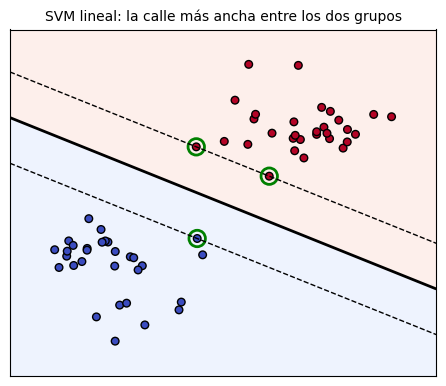

Vectores de soporte: 3 de 60 puntos
Ancho de la calle (margen): 2.33


In [2]:
Xb, yb = make_blobs(n_samples=60, centers=[(-2, -2), (2, 2)], cluster_std=0.9, random_state=4)

fig, ax = plt.subplots(figsize=(5.5, 4.5))
svm = SVC(kernel="linear", C=1000)          # C muy alto = 'no tolero errores' (ver más abajo)
dibujar_svm(svm, Xb, yb, ax, "SVM lineal: la calle más ancha entre los dos grupos")
plt.show()

w = svm.coef_[0]
print("Vectores de soporte:", len(svm.support_vectors_), "de", len(Xb), "puntos")
print("Ancho de la calle (margen):", round(2 / np.linalg.norm(w), 2))

Fíjate: solo **un puñado de puntos** (los círculos verdes) sostiene toda la frontera. Los demás clientes, aunque estén lejos, no influyen.

## 2. Parámetro `C`: ¿perdono errores o exijo perfección?
Los datos reales **se mezclan** (siempre hay clientes que se van aunque parezcan fieles). Entonces hay que decidir: ¿prefiero una calle ancha aceptando algunos errores o una calle estrecha que no falle ningún punto?

* **`C` chico** (0,01): *"tolero errores"* → calle **ancha** y suave; modelo más simple (riesgo de underfitting).
* **`C` grande** (100-1000): *"no tolero ningún error"* → calle **estrecha** que se retuerce para no fallar (riesgo de overfitting).

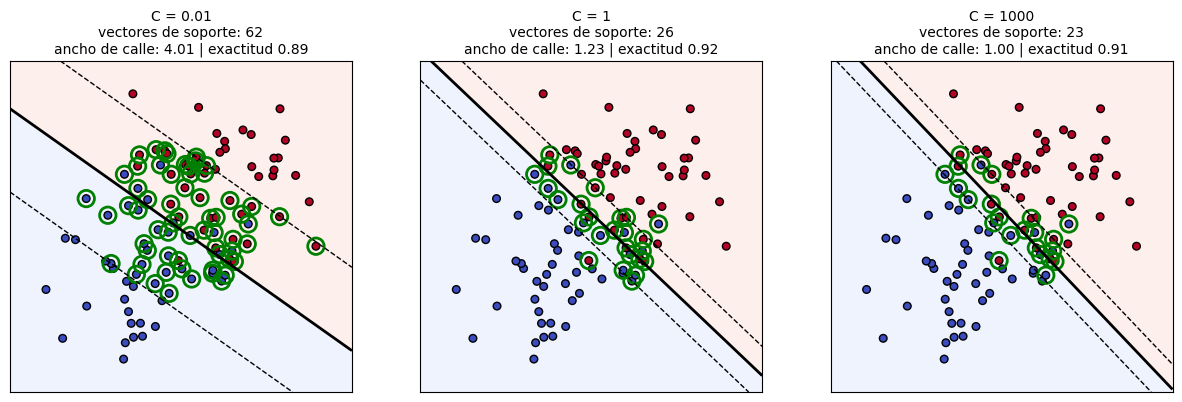

In [3]:
Xo, yo = make_blobs(n_samples=100, centers=[(-1.2, -1.2), (1.2, 1.2)], cluster_std=1.3, random_state=7)

fig, ejes = plt.subplots(1, 3, figsize=(15, 4.3))
for ax, C in zip(ejes, [0.01, 1, 1000]):
    m = SVC(kernel="linear", C=C)
    dibujar_svm(m, Xo, yo, ax, "")
    ancho = 2 / np.linalg.norm(m.coef_[0])
    ax.set_title(f"C = {C}\nvectores de soporte: {len(m.support_vectors_)}\nancho de calle: {ancho:.2f} | exactitud {m.score(Xo, yo):.2f}", fontsize=10)
plt.show()

**Cómo leerlo:**
* `C=0.01`: calle **muy ancha**, casi todos los puntos son vectores de soporte; el modelo es muy tolerante.
* `C=1`: equilibrio.
* `C=1000`: calle **angosta**; intenta clasificar bien hasta los puntos "mal ubicados".

> **Regla práctica:** `C` chico = simple y tolerante. `C` grande = estricto y propenso a memorizar. Se elige con validación cruzada o grid search.

## 3. Parámetro `kernel`: separar grupos que no se separan con una recta
¿Y si un grupo rodea a otro (como una dona)? Ninguna recta lo separa. El **kernel** es un truco matemático: **proyecta los puntos a una dimensión superior donde sí se pueden separar con un plano**, y luego "regresa" la frontera al dibujo original como una **curva**.

| Kernel | Forma de la frontera | Cuándo usarlo |
|---|---|---|
| `"linear"` | Recta / plano | Datos casi separables con una recta; muchas variables; es el más rápido. |
| `"poly"` | Curva polinómica (parábolas, etc.) | Relaciones con curvas suaves. Parámetros: `degree` (grado), `coef0`. |
| `"rbf"` | Curvas flexibles, "manchas" alrededor de los grupos | **Opción por defecto** y casi siempre la mejor primera opción. Parámetro: `gamma`. |
| `"sigmoid"` | Parecido a una red neuronal sencilla | Rara vez se usa. |

### Ejemplo 2 · Los grupos en forma de dona (círculos)

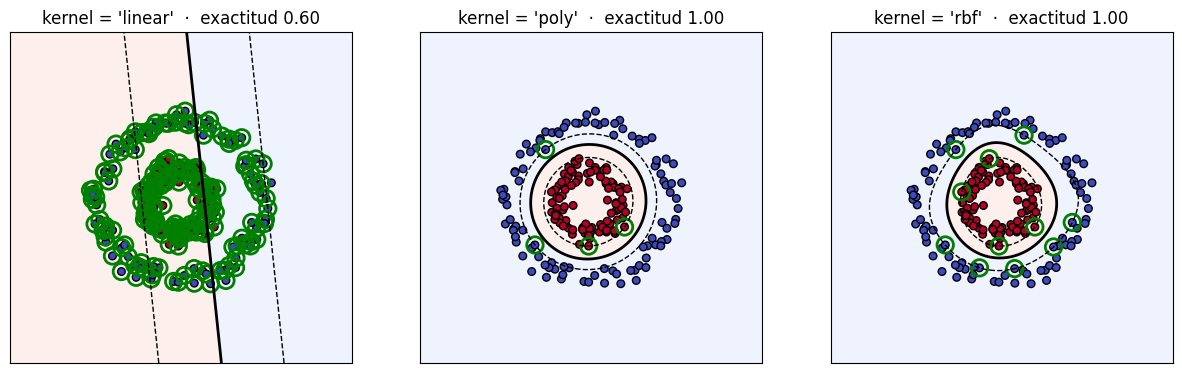

In [4]:
Xc, yc = make_circles(n_samples=200, noise=0.08, factor=0.4, random_state=1)

fig, ejes = plt.subplots(1, 3, figsize=(15, 4.3))
for ax, (k, extra) in zip(ejes, [("linear", {}), ("poly", {"degree": 2}), ("rbf", {})]):
    m = SVC(kernel=k, C=10, **extra)
    dibujar_svm(m, Xc, yc, ax, "")
    ax.set_title(f"kernel = '{k}'  ·  exactitud {m.score(Xc, yc):.2f}")
plt.show()

* **linear**: una recta no puede separar una dona: ~50 %.
* **poly (grado 2)** y **rbf**: dibujan una **curva cerrada** alrededor del grupo interior → ~100 %.

### Ejemplo 3 · Las medias lunas (otra forma común)

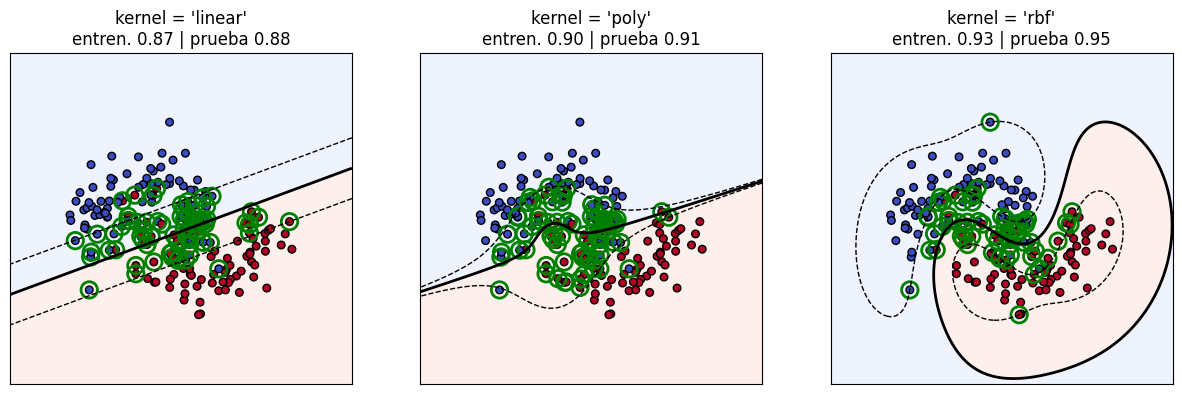

In [5]:
Xm, ym = make_moons(n_samples=250, noise=0.25, random_state=3)
Xm_tr, Xm_te, ym_tr, ym_te = train_test_split(Xm, ym, test_size=0.3, random_state=0)

fig, ejes = plt.subplots(1, 3, figsize=(15, 4.3))
for ax, (k, extra) in zip(ejes, [("linear", {}), ("poly", {"degree": 3}), ("rbf", {})]):
    m = SVC(kernel=k, C=1, **extra)
    dibujar_svm(m, Xm_tr, ym_tr, ax, "")
    ax.set_title(f"kernel = '{k}'\nentren. {m.score(Xm_tr, ym_tr):.2f} | prueba {m.score(Xm_te, ym_te):.2f}")
plt.show()

Con las lunas, el kernel **lineal** se queda corto; **poly** y **rbf** siguen la forma. Si no sabes cuál usar: **empieza con `rbf`**.

## 4. Parámetro `gamma` (solo kernels `rbf`, `poly`, `sigmoid`)
`gamma` controla **qué tan lejos llega la influencia de cada punto**:
* **`gamma` chico**: cada punto influye en una zona **amplia** → frontera suave y simple (riesgo de underfitting).
* **`gamma` grande**: cada punto influye solo en su **vecindario inmediato** → frontera muy detallada que rodea puntos sueltos (**overfitting**).

Analogía: `gamma` es el **radio de una linterna** que cada cliente enciende. Con luz amplia todo se mezcla; con luz muy estrecha solo ilumina a sí mismo.

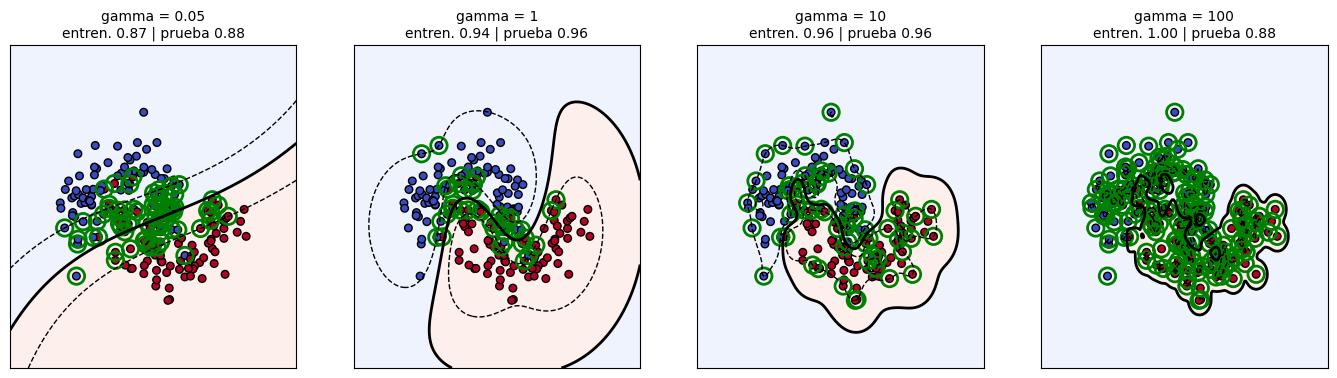

In [6]:
fig, ejes = plt.subplots(1, 4, figsize=(17, 4.2))
for ax, g in zip(ejes, [0.05, 1, 10, 100]):
    m = SVC(kernel="rbf", C=10, gamma=g)
    dibujar_svm(m, Xm_tr, ym_tr, ax, "")
    ax.set_title(f"gamma = {g}\nentren. {m.score(Xm_tr, ym_tr):.2f} | prueba {m.score(Xm_te, ym_te):.2f}", fontsize=10)
plt.show()

**Cómo leerlo:**
* `gamma=0.05`: la frontera es casi una línea (*underfitting*).
* `gamma=1` y `gamma=10`: siguen la forma con suavidad y la prueba es la mejor (**zona buena**).
* `gamma=10-100`: aparecen "islas" alrededor de puntos individuales; el **entrenamiento sube a ~1,0** pero la **prueba baja** (*overfitting*).

> **`gamma="scale"`** (valor por defecto en scikit-learn) calcula un valor razonable a partir de los datos. Suele ser un muy buen punto de partida.

### La pareja `C` y `gamma`
Ambos controlan la complejidad y **se ajustan juntos**: `C` alto + `gamma` alto = modelo muy complejo (overfitting). `C` bajo + `gamma` bajo = muy simple (underfitting).

## 5. Parámetros de `SVC` (resumen)
| Parámetro | Qué hace | Por defecto | Qué pasa si lo cambias |
|---|---|---|---|
| **`C`** | Tolerancia a errores (ancho de calle). | `1.0` | Chico → simple/tolerante. Grande → estricto/overfitting. |
| **`kernel`** | Forma de la frontera. | `"rbf"` | `linear` para rectas; `rbf` para curvas flexibles; `poly` para polinomios. |
| **`gamma`** | Alcance de la influencia de cada punto. | `"scale"` | Chico → suave. Grande → detallado/overfitting. |
| **`degree`** | Grado del polinomio (solo `poly`). | `3` | Mayor grado = curvas más complejas. |
| **`coef0`** | Término independiente en `poly`/`sigmoid`. | `0.0` | Rara vez se toca. |
| **`class_weight`** | Peso por clase. | `None` | `"balanced"` para clases desbalanceadas (más recall). |
| **`probability`** | Si calcula probabilidades (`predict_proba`). | `False` | `True` las habilita pero **entrena más lento** (usa validación cruzada interna). |
| **`max_iter`** | Máximo de iteraciones. | `-1` (sin límite) | Útil para evitar entrenamientos eternos. |
| **`random_state`** | Semilla. | `None` | Importante si `probability=True`. |

## 6. Aplicado a los datos reales (caso operadora móvil)

## Preparar los datos reales (caso operadora móvil)
Usamos el mismo archivo de las semanas 3 y 4: `clientes_telecom.csv`. Queremos predecir `se_fue` (1 = el cliente se fue, 0 = se quedó).

Aquí solo hacemos lo indispensable: limpieza mínima, separar una parte para **validar** y convertir las columnas a números (rellenar vacíos, escalar y pasar categorías a 0/1). Si no entiendes esta celda, no importa: **ejecútala tal cual** y sigue.

In [7]:
# Cargamos el archivo desde el repositorio del curso.
# Si no hay internet, sube clientes_telecom.csv al panel de archivos de Colab y cambia URL por "clientes_telecom.csv".
URL = "https://raw.githubusercontent.com/jeanpier22/Diseno-de-Soluciones-de-Inteligencia-Artificial/main/Practica_Semana3y4/clientes_telecom.csv"
df = pd.read_csv(URL, encoding="utf-8-sig")

# Limpieza mínima (la misma de la Sesión 5)
df = df.drop_duplicates(subset="id_cliente").copy()
df.loc[(df["edad"] < 14) | (df["edad"] > 100), "edad"] = np.nan
df.loc[df["monto_factura"] < 0, "monto_factura"] = np.nan
df["tipo_plan"] = (df["tipo_plan"].str.lower().str.replace("-", "", regex=False)
                   .replace({"prepago": "Prepago", "postpago ilimitado": "Postpago Ilimitado", "postpago básico": "Postpago Básico"}))

num = ["edad", "consumo_datos_mb", "minutos_llamadas", "recargas_mes", "monto_factura",
       "velocidad_mbps", "caidas_red_mes", "llamadas_soporte", "satisfaccion"]
cat = ["tipo_plan", "metodo_pago", "departamento"]

train = df[df["particion"] == "train"]
X_train, y_train = train[num + cat], train["se_fue"]

# Del 'train' separamos una parte para VALIDAR (examen de práctica). El 'test' no se toca en este cuaderno.
X_tr, X_val, y_tr, y_val = train_test_split(X_train, y_train, test_size=0.25, stratify=y_train, random_state=SEMILLA)

prep = ColumnTransformer([
    ("num", Pipeline([("imp", SimpleImputer(strategy="median")), ("esc", StandardScaler())]), num),
    ("cat", Pipeline([("imp", SimpleImputer(strategy="most_frequent")),
                      ("oh", OneHotEncoder(handle_unknown="ignore"))]), cat),
], sparse_threshold=0)

Xp_tr = prep.fit_transform(X_tr)      # se 'aprende' solo con entrenamiento
Xp_val = prep.transform(X_val)
nombres = [n.split("__", 1)[1] for n in prep.get_feature_names_out()]
print("Clientes para entrenar:", Xp_tr.shape[0], "| para validar:", Xp_val.shape[0], "| columnas:", Xp_tr.shape[1])
print("Proporción que se va:", round(y_tr.mean(), 3))

Clientes para entrenar: 900 | para validar: 300 | columnas: 31
Proporción que se va: 0.288


### Primer modelo SVM con parámetros por defecto

In [8]:
svm = SVC(kernel="rbf", C=1, gamma="scale")
svm.fit(Xp_tr, y_tr)
print("SVM por defecto en validación:")
print(metricas(svm, Xp_val, y_val))
print("Vectores de soporte:", svm.n_support_.sum(), "de", len(y_tr), "clientes de entrenamiento")

SVM por defecto en validación:
exactitud    0.773
precisión    0.705
recall       0.360
F1           0.477
AUC          0.788
dtype: float64
Vectores de soporte: 540 de 900 clientes de entrenamiento


> **Nota técnica:** `SVC` no da probabilidades por defecto, pero tiene `decision_function` (qué tan lejos está cada cliente de la frontera). El AUC se puede calcular con ese puntaje; eso es lo que hace nuestra función `metricas`.

### Experimento A · La importancia de escalar
La SVM mide **distancias** entre clientes. Si una variable está en miles (MB de datos) y otra entre 1 y 5 (satisfacción), la de los miles **domina** la distancia y las otras casi no cuentan.

In [9]:
cols = ["consumo_datos_mb", "minutos_llamadas", "satisfaccion", "llamadas_soporte", "caidas_red_mes"]
Xn_tr = X_tr[cols].fillna(X_tr[cols].median())
Xn_val = X_val[cols].fillna(X_tr[cols].median())

sin = SVC(kernel="rbf").fit(Xn_tr, y_tr)
con = make_pipeline(StandardScaler(), SVC(kernel="rbf")).fit(Xn_tr, y_tr)

pd.DataFrame({"SIN escalar": metricas(sin, Xn_val, y_val), "CON escalar": metricas(con, Xn_val, y_val)})

,SIN escalar,CON escalar
exactitud,0.713,0.750
precisión,0.000,0.704
recall,0.000,0.221
F1,0.000,0.336
AUC,0.602,0.702


Sin escalar, la SVM queda dominada por `consumo_datos_mb` y `minutos_llamadas` (miles) y **ni siquiera detecta a un solo cliente que se va** (recall 0, precisión 0: dice "se queda" a todos), con AUC ~0,60. Escalado sube a ~0,70. **Con SVM siempre escala** (`StandardScaler`).

### Experimento B · Barrido de `C` en datos reales

,C,AUC entrenamiento,AUC validación,vectores de soporte
0,0.01,0.841,0.809,549
1,0.10,0.841,0.809,551
2,1.00,0.892,0.788,540
3,10.00,0.983,0.689,538
4,100.00,1.000,0.630,503
5,1000.00,1.000,0.626,492


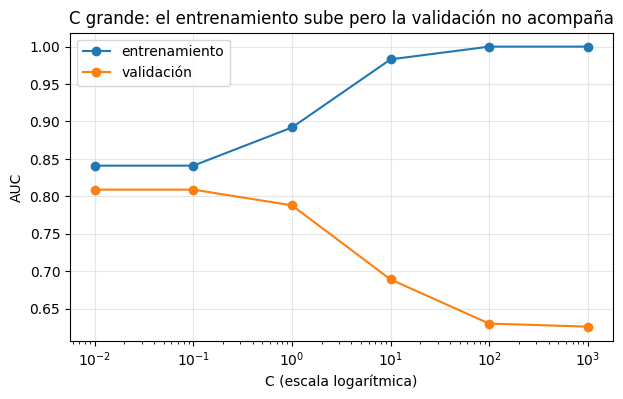

In [10]:
filas = []
for C in [0.01, 0.1, 1, 10, 100, 1000]:
    m = SVC(kernel="rbf", C=C, gamma="scale").fit(Xp_tr, y_tr)
    filas.append({"C": C,
                  "AUC entrenamiento": roc_auc_score(y_tr, m.decision_function(Xp_tr)),
                  "AUC validación": roc_auc_score(y_val, m.decision_function(Xp_val)),
                  "vectores de soporte": int(m.n_support_.sum())})
res = pd.DataFrame(filas).round(3)
display(res)
plt.semilogx(res["C"], res["AUC entrenamiento"], "o-", label="entrenamiento")
plt.semilogx(res["C"], res["AUC validación"], "o-", label="validación")
plt.xlabel("C (escala logarítmica)"); plt.ylabel("AUC"); plt.legend()
plt.title("C grande: el entrenamiento sube pero la validación no acompaña"); plt.show()

Aquí los **mejores** valores de validación están en `C` chico (0,01–0,1, AUC ~0,81). Al subir `C` el AUC de **entrenamiento** llega a 1,0 pero el de **validación se desploma** (0,63 con `C=1000`): es **overfitting** clarísimo. La SVM con kernel `rbf` es muy flexible y con `C` alto memoriza.

### Experimento C · Mapa de calor `C × gamma` (búsqueda en cuadrícula)
Probamos **todas las combinaciones** y medimos el AUC con **validación cruzada** (3 pliegues). Es lo que hace `GridSearchCV` por dentro. Las zonas más claras son las mejores.

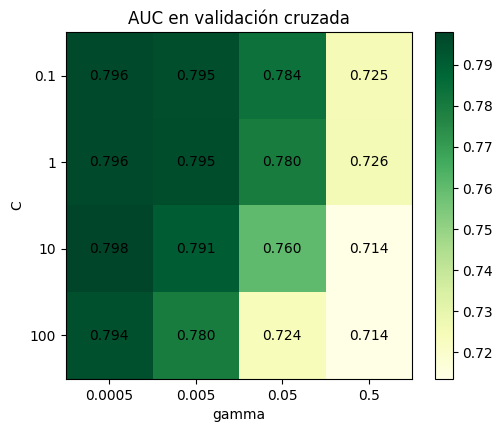

Mejor combinación: C=10, gamma=0.0005  ->  AUC 0.798


In [11]:
Cs = [0.1, 1, 10, 100]
gammas = [0.0005, 0.005, 0.05, 0.5]
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEMILLA)

mapa = np.zeros((len(Cs), len(gammas)))
for i, C in enumerate(Cs):
    for j, g in enumerate(gammas):
        mapa[i, j] = cross_val_score(SVC(kernel="rbf", C=C, gamma=g), Xp_tr, y_tr, cv=cv, scoring="roc_auc").mean()

fig, ax = plt.subplots(figsize=(6, 4.5))
im = ax.imshow(mapa, cmap="YlGn")
ax.set_xticks(range(len(gammas))); ax.set_xticklabels(gammas); ax.set_xlabel("gamma")
ax.set_yticks(range(len(Cs))); ax.set_yticklabels(Cs); ax.set_ylabel("C")
for i in range(len(Cs)):
    for j in range(len(gammas)):
        ax.text(j, i, f"{mapa[i, j]:.3f}", ha="center", va="center")
ax.grid(False); ax.set_title("AUC en validación cruzada"); plt.colorbar(im); plt.show()

i, j = np.unravel_index(mapa.argmax(), mapa.shape)
print(f"Mejor combinación: C={Cs[i]}, gamma={gammas[j]}  ->  AUC {mapa[i, j]:.3f}")

**Cómo leerlo:** hay una **zona buena** en el mapa (combinaciones intermedias). Las esquinas con `C` y `gamma` ambos altos suelen ser malas (overfitting) y con ambos muy bajos también (underfitting). En el proyecto lo harás con `GridSearchCV` en una línea.

### Experimento D · `class_weight` y umbral
Si te importa **detectar a quien se va**, puedes pedir a la SVM que penalice más los errores en esa clase:

In [12]:
normal = SVC(kernel="rbf", C=1).fit(Xp_tr, y_tr)
balanceada = SVC(kernel="rbf", C=1, class_weight="balanced").fit(Xp_tr, y_tr)
pd.DataFrame({"sin class_weight": metricas(normal, Xp_val, y_val), "balanced": metricas(balanceada, Xp_val, y_val)})

,sin class_weight,balanced
exactitud,0.773,0.743
precisión,0.705,0.541
recall,0.360,0.686
F1,0.477,0.605
AUC,0.788,0.804


Con `balanced` el **recall sube** (detectas más clientes que se van) a costa de la **precisión** (más falsas alarmas): el mismo vaivén de siempre.

### Experimento E · `probability=True`: cuando necesitas probabilidades
Por defecto la SVM da solo "sí/no". Si necesitas un porcentaje (por ejemplo, para ordenar a los clientes por riesgo o mover el umbral), activa `probability=True`. Cuesta más tiempo de entrenamiento.

In [13]:
svm_prob = SVC(kernel="rbf", C=1, probability=True, random_state=SEMILLA).fit(Xp_tr, y_tr)
probas = svm_prob.predict_proba(Xp_val)[:, 1]
print("Primeros 8 clientes de validación -> probabilidad de irse:", probas[:8].round(2))
print("AUC con probabilidades:", round(roc_auc_score(y_val, probas), 3))

Primeros 8 clientes de validación -> probabilidad de irse: [0.1  0.21 0.18 0.42 0.1  0.64 0.35 0.33]
AUC con probabilidades: 0.788


## 7. SVM para predecir números: `SVR`
La versión de regresión se llama **SVR**. En lugar de una "calle" que separa grupos, dibuja un **tubo** alrededor de la curva: los puntos **dentro del tubo no cuentan como error**. El ancho del tubo es el parámetro **`epsilon`**.

* `epsilon` chico → tubo estrecho → el modelo exige precisión (más detalle).
* `epsilon` grande → tubo ancho → tolera más desvío (curva más simple).

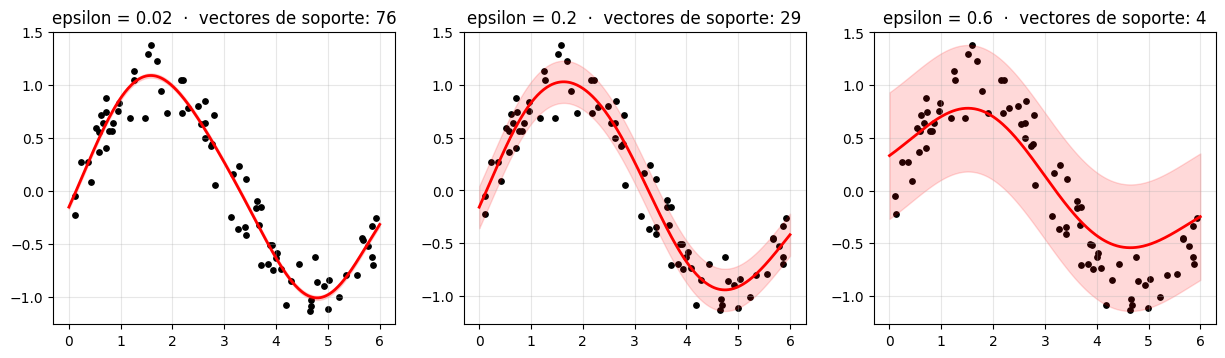

In [14]:
rng = np.random.RandomState(0)
x = np.sort(rng.uniform(0, 6, 80)); y = np.sin(x) + rng.normal(0, 0.2, 80)
xs = np.linspace(0, 6, 300).reshape(-1, 1)

fig, ejes = plt.subplots(1, 3, figsize=(15, 3.8))
for ax, eps in zip(ejes, [0.02, 0.2, 0.6]):
    r = SVR(kernel="rbf", C=10, epsilon=eps).fit(x.reshape(-1, 1), y)
    p = r.predict(xs)
    ax.scatter(x, y, s=15, color="k")
    ax.plot(xs, p, "r", lw=2)
    ax.fill_between(xs.ravel(), p - eps, p + eps, color="red", alpha=.15)
    ax.set_title(f"epsilon = {eps}  ·  vectores de soporte: {len(r.support_)}")
plt.show()

Con tubo estrecho casi todos los puntos son vectores de soporte; con tubo ancho solo los muy alejados. `SVR` también usa `C`, `kernel` y `gamma` con el mismo significado que en `SVC`.

## 8. Resumen: ¿qué mover y cuándo?
| Síntoma que ves | Qué probar |
|---|---|
| Entrenamiento ≈ 1,0 y validación mucho menor (**overfitting**) | Bajar `C`; bajar `gamma`; reducir el grado en `poly`. |
| Ambas notas bajas (**underfitting**) | Subir `C`; subir `gamma`; cambiar a un kernel más flexible (`rbf`). |
| Detecta pocos clientes que se van | `class_weight="balanced"`; mover el umbral usando `probability=True`. |
| El entrenamiento es muy lento | Escalar bien; usar `LinearSVC` con datos grandes; reducir columnas o filas. |
| Resultados raros | ¿Escalaste las variables? (¡es el error nº 1!). |

### Receta para empezar
`make_pipeline(StandardScaler(), SVC(kernel="rbf", C=1, gamma="scale"))` y luego `GridSearchCV` sobre `C` y `gamma` con valores en escala logarítmica (`0.1, 1, 10, 100`).

### Ventajas y límites
| ✅ Ventajas | ⚠️ Límites |
|---|---|
| Muy buena con **pocos o medianos datos** y muchas variables. | **Lenta** con muchos datos (decenas de miles de filas o más). |
| Con kernel `rbf` capta fronteras curvas muy complejas. | Necesita **escalar** sí o sí. |
| Solo depende de los vectores de soporte (robusta ante puntos lejanos). | Poco explicable (no da coeficientes simples con `rbf`) y no da probabilidades directas. |

> **Dato de la Sesión 5:** en nuestros datos de churn la SVM obtuvo precisión alta (~0,70) pero **recall bajo (~0,36)**: acierta cuando dice "se va", pero **deja pasar a muchos**. La logística terminó ganando por mejor AUC y por ser explicable.

## 9. Ejercicios
1. En el ejemplo de `C` con datos mezclados, prueba `C=0.001` y `C=10000`. ¿Cuántos vectores de soporte hay en cada caso?
2. En las medias lunas, prueba `kernel="poly"` con `degree=1, 3, 8`. ¿Cuál sobreajusta?
3. Con `gamma=100` y `C=1000` el modelo debería memorizar: ¿cuánto vale la exactitud de entrenamiento y la de prueba?
4. En los datos reales, prueba `class_weight={0: 1, 1: 3}` y compara el recall.
5. Para tu Evidencia 3: con el mapa `C × gamma` elige la mejor combinación y justifica en 3 líneas por qué es la mejor y qué riesgo de overfitting tiene.